# 04: Customer lifetime value and churn
**Goal:** predict who will keep buying, how much they are worth, and who is likely gone.

We use two models from the `lifetimes` library. They are built for stores like this one, where customers buy whenever they want and never "cancel":
- **BG/NBD:** predicts *how many more purchases* a customer will make, and the chance they are still active.
- **Gamma-Gamma:** predicts *how much each purchase will be worth*.

Multiply them and you get predicted lifetime value (LTV). We also build a simple churn model to compare against BG/NBD.

Install once if needed: `pip install lifetimes scikit-learn`

## Step 1: Load the clean sales
Same filter as the gold notebook: only customers with an ID, and no cancellations, returns, or bad prices. We then add up each customer's invoices **per day**, because BG/NBD counts one purchase per customer per day.

In [ ]:
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.utils import summary_data_from_transaction_data
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, mean_absolute_error, mean_squared_error

PROJECT_ROOT = Path.cwd().parent
DB_PATH = PROJECT_ROOT / "data" / "ltv.duckdb"

with duckdb.connect(str(DB_PATH)) as con:
    silver = con.sql("""SELECT Customer_ID, InvoiceDate, Quantity, Price,
                               Customer_ID_Exists, Cancelled_Order, Return_Adjustment
                        FROM silver""").df()

sales = silver[silver["Customer_ID_Exists"]
               & ~silver["Cancelled_Order"]
               & ~silver["Return_Adjustment"]
               & (silver["Quantity"] > 0)
               & (silver["Price"] > 0)].copy()
sales["InvoiceDate"] = pd.to_datetime(sales["InvoiceDate"])
sales["line_total"] = sales["Quantity"] * sales["Price"]

#one row per customer per day
orders = sales.groupby(["Customer_ID", "InvoiceDate"])["line_total"].sum().reset_index()
print(f"{len(orders):,} customer-days, {orders['Customer_ID'].nunique():,} customers")
print(f"Data runs {orders['InvoiceDate'].min().date()} to {orders['InvoiceDate'].max().date()}")

33,107 customer-days, 5,878 customers
Data runs 2009-12-01 to 2011-12-09


## Step 2: Split time into "past" and "future"
To test this model, we set the day to **June 9, 2011**. Remember, our data range is December 2009 - December 2011. The model only sees purchases before that date (the **calibration** period). Then we check its predictions against what customers *actually* did afterward (the **holdout** period, about 6 months).

We split by date, not randomly, because a random split would let the model peek at the future.

`summary_data_from_transaction_data` turns the orders into the three numbers BG/NBD needs per customer:
- **frequency:** number of *repeat* purchases (first purchase doesn't count)
- **recency:** days between their first and last purchase
- **T:** days between their first purchase and the cutoff date (their age)

In [ ]:
cutoff = pd.Timestamp("2011-06-09")
end = orders["InvoiceDate"].max()
holdout_days = (end - cutoff).days

past = orders[orders["InvoiceDate"] <= cutoff]
future = orders[orders["InvoiceDate"] > cutoff]

rfm = summary_data_from_transaction_data(
    past, "Customer_ID", "InvoiceDate", "line_total", observation_period_end=cutoff)

#What each customer actually did in the holdout period
rfm["actual_purchases"] = future.groupby("Customer_ID").size().reindex(rfm.index, fill_value=0)

print(f"Holdout is {holdout_days} days. Customers seen before the cutoff: {len(rfm):,}")
rfm.head()

Holdout is 183 days. Customers seen before the cutoff: 4,969


,frequency,recency,T,monetary_value,actual_purchases
Customer_ID,,,,,
12346,7.0,400.0,542.0,11066.637143,0
12347,4.0,221.0,221.0,729.435000,3
12348,3.0,190.0,255.0,495.746667,1
12349,2.0,182.0,406.0,801.310000,1
12350,0.0,0.0,127.0,0.000000,0


## Step 3: Fit BG/NBD and predict future sales
We fit the model on the past only, then ask it two things for every customer:
- `pred_purchases`: how many purchases it expects in the holdout period
- `p_alive`: the probability the customer is still active (close to 1 = active, close to 0 = probably gone)

`penalizer_coef` is a safety setting that keeps the fit stable.

In [10]:
bgf = BetaGeoFitter(penalizer_coef=0.001)
bgf.fit(rfm["frequency"], rfm["recency"], rfm["T"])

rfm["pred_purchases"] = bgf.conditional_expected_number_of_purchases_up_to_time(
    holdout_days, rfm["frequency"], rfm["recency"], rfm["T"])
rfm["p_alive"] = bgf.conditional_probability_alive(rfm["frequency"], rfm["recency"], rfm["T"])

rfm[["frequency", "recency", "T", "actual_purchases", "pred_purchases", "p_alive"]].head()

,frequency,recency,T,actual_purchases,pred_purchases,p_alive
Customer_ID,,,,,,
12346,7.0,400.0,542.0,0,2.097844,0.917748
12347,4.0,221.0,221.0,3,2.863224,0.980652
12348,3.0,190.0,255.0,1,1.940785,0.944035
12349,2.0,182.0,406.0,1,0.847013,0.827648
12350,0.0,0.0,127.0,0,0.621369,1.000000


## Step 4: Model Evaluation
Comparing predicted purchases to actual purchases in the holdout:
- **MAE** is the average miss per customer, in purchases.
- **RMSE** is similar, but it punishes big misses more.
- The chart groups customers by how many repeat purchases they had before the cutoff. If the bars are close, the model is well calibrated. (The last group is "6 or more".)

MAE:  1.047 purchases per customer
RMSE: 1.773 purchases per customer


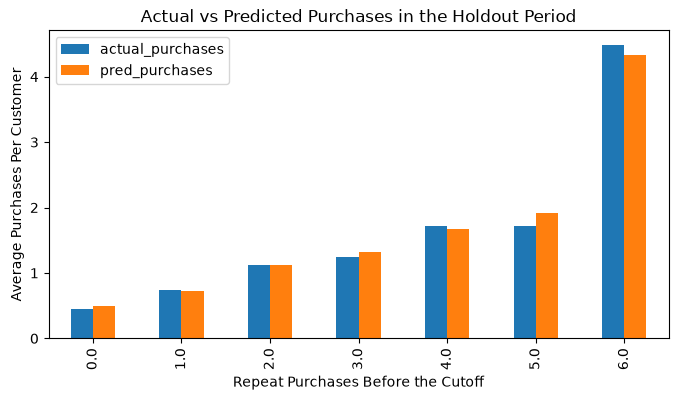

In [12]:
mae = mean_absolute_error(rfm["actual_purchases"], rfm["pred_purchases"])
rmse = np.sqrt(mean_squared_error(rfm["actual_purchases"], rfm["pred_purchases"]))
print(f"MAE:  {mae:.3f} purchases per customer")
print(f"RMSE: {rmse:.3f} purchases per customer")

rfm["freq_group"] = rfm["frequency"].clip(upper=6)
check = rfm.groupby("freq_group")[["actual_purchases", "pred_purchases"]].mean()
check.plot(kind="bar", figsize=(8, 4), title="Actual vs Predicted Purchases in the Holdout Period")
plt.xlabel("Repeat Purchases Before the Cutoff")
plt.ylabel("Average Purchases Per Customer")
plt.show()

## Step 5: Customer lifetime value (LTV)
Now we use *all* the data (not just the past) to predict the next 12 months for each customer:

**predicted LTV = expected purchases in 12 months (BG/NBD) x expected order value (Gamma-Gamma)**

Three things to know:
- **Gamma-Gamma assumes** that how much a customer spends per order doesn't depend on how often they order. We check that first. A correlation near 0 is good.
- **Wholesale buyers** with orders of $10,000+ break the model, so we cap each customer's average order at the 95th percentile (roughly $1,000). This means our LTV for the very biggest buyers is understated, which is the safe direction.
- **One-time buyers** have no repeat orders for Gamma-Gamma to learn from, so we give them the average repeat-buyer order value.

In [5]:
full = summary_data_from_transaction_data(
    orders, "Customer_ID", "InvoiceDate", "line_total", observation_period_end=end)
full["repeat_buyer"] = full["frequency"] > 0

# cap huge wholesale orders
cap = full.loc[full["repeat_buyer"], "monetary_value"].quantile(0.95)
full["monetary_value"] = full["monetary_value"].clip(upper=cap)
repeat = full[full["repeat_buyer"]]
print(f"Order value cap: ${cap:,.0f}")
print("Correlation between order count and order value:")
print(repeat[["frequency", "monetary_value"]].corr().round(3))

# model 1: how many purchases in the next 12 months?
bgf_all = BetaGeoFitter(penalizer_coef=0.001).fit(full["frequency"], full["recency"], full["T"])
full["p_alive"] = bgf_all.conditional_probability_alive(full["frequency"], full["recency"], full["T"])
full["pred_purchases_12m"] = bgf_all.conditional_expected_number_of_purchases_up_to_time(
    365, full["frequency"], full["recency"], full["T"])

# model 2: how much is each purchase worth?
ggf = GammaGammaFitter(penalizer_coef=0.001).fit(repeat["frequency"], repeat["monetary_value"])
full["pred_order_value"] = repeat["monetary_value"].mean()          # one-time buyers get the average
full.loc[full["repeat_buyer"], "pred_order_value"] = ggf.conditional_expected_average_profit(
    repeat["frequency"], repeat["monetary_value"])

full["ltv_12m"] = full["pred_purchases_12m"] * full["pred_order_value"]
print(f"\nTotal predicted 12-month revenue: ${full['ltv_12m'].sum():,.0f}")
full[["frequency", "pred_purchases_12m", "pred_order_value", "ltv_12m"]].describe().round(2)

Order value cap: $997
Correlation between order count and order value:
                frequency  monetary_value
frequency           1.000           0.181
monetary_value      0.181           1.000

Total predicted 12-month revenue: $7,621,165


,frequency,pred_purchases_12m,pred_order_value,ltv_12m
count,5878.00,5878.00,5878.00,5878.00
mean,4.63,3.17,366.22,1296.56
std,10.00,4.86,199.33,3053.67
min,0.00,0.00,12.11,0.00
25%,0.00,0.69,241.48,191.51
50%,2.00,1.81,361.83,541.28
75%,5.00,3.88,381.83,1302.68
max,254.00,114.30,1016.58,113925.27


## Step 6: Where does the value sit?
We rank customers from lowest to highest predicted LTV and cut them into 10 equal groups (decile 10 = best). If most of the value is in decile 10, we know where retention money should go.

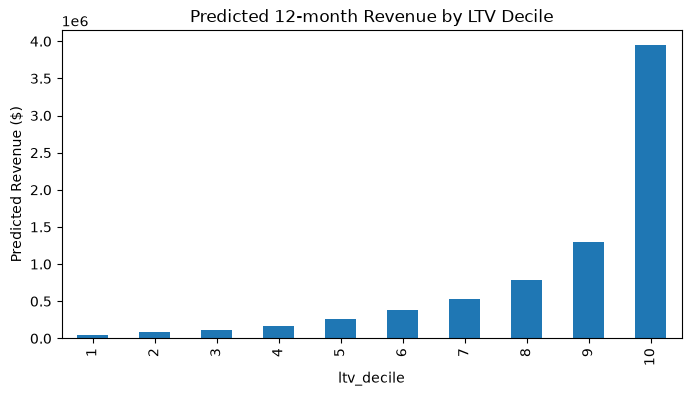

The top 10% of Customers Hold 52% of Predicted Revenue


In [13]:
full["ltv_decile"] = pd.qcut(full["ltv_12m"].rank(method="first"), 10, labels=False) + 1
by_decile = full.groupby("ltv_decile")["ltv_12m"].sum()
top10_share = by_decile.loc[10] / by_decile.sum()

by_decile.plot(kind="bar", figsize=(8, 4), title="Predicted 12-month Revenue by LTV Decile")
plt.ylabel("Predicted Revenue ($)")
plt.show()
print(f"The top 10% of Customers Hold {top10_share:.0%} of Predicted Revenue")

## Step 7: Comparing with a churn model
BG/NBD gives a churn probability (1 minus `p_alive`), but we also want to compare it with a basic machine learning model for a sanity check.

**Definition:** a customer *churned* if they bought before June 9, 2011 and **did not buy at all** in the next ~6 months.

**Repeat buyers only:** BG/NBD gives every one-time buyer a `p_alive` of 1 (it has no evidence yet that they left), so it can't rank them. We compare the two models fairly on repeat buyers. One-time buyers are a separate group, and most of them (74%) never came back, which is a finding for notebook 05.

We train a logistic regression on the past numbers (frequency, recency, age, average order value) and keep 30% of customers aside for testing. **AUC** measures how well a score separates churners from non-churners: 0.5 is a coin flip, 1.0 is perfect.

In [7]:
rfm["churned"] = (rfm["actual_purchases"] == 0).astype(int)
print(f"Churned, one-time buyers:  {rfm.loc[rfm['frequency'] == 0, 'churned'].mean():.0%}")
print(f"Churned, repeat buyers:    {rfm.loc[rfm['frequency'] > 0, 'churned'].mean():.0%}")

rep = rfm[rfm["frequency"] > 0]
features = ["frequency", "recency", "T", "monetary_value"]
train, test = train_test_split(rep, test_size=0.3, random_state=42, stratify=rep["churned"])

logit = make_pipeline(StandardScaler(), LogisticRegression())
logit.fit(train[features], train["churned"])

auc_logit = roc_auc_score(test["churned"], logit.predict_proba(test[features])[:, 1])
auc_bgnbd = roc_auc_score(test["churned"], 1 - test["p_alive"])
print(f"\nAUC, logistic regression: {auc_logit:.3f}")
print(f"AUC, BG/NBD (1 - p_alive): {auc_bgnbd:.3f}")

Churned, one-time buyers:  74%
Churned, repeat buyers:    36%

AUC, logistic regression: 0.781
AUC, BG/NBD (1 - p_alive): 0.782


## Step 8: Save the results for notebook 05 segment recommendations
We save one row per customer with their churn risk and predicted LTV. Notebook 05 uses this file to build customer segments and campaign recommendations.

Churn risk comes from BG/NBD (fit on all the data). It is only meaningful for repeat buyers, so we keep the `repeat_buyer` column to treat one-time buyers separately later.

In [14]:
scores = full.reset_index()[["Customer_ID", "repeat_buyer", "frequency", "recency", "T", "monetary_value",
                                "p_alive", "pred_purchases_12m", "pred_order_value", "ltv_12m", "ltv_decile"]]
scores["churn_risk"] = 1 - scores["p_alive"]

EXPORT_DIR = PROJECT_ROOT / "data" / "exports"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
scores.to_csv(EXPORT_DIR / "customer_scores.csv", index=False)
print(f"Saved {len(scores):,} customers to data/exports/customer_scores.csv")
scores.head().style.format({
    "frequency": "{:.0f}",
    "recency": "{:.0f}",
    "T": "{:.0f}",
    "monetary_value": "${:,.0f}",
    "p_alive": "{:.1%}",
    "pred_purchases_12m": "{:.2f}",
    "pred_order_value": "${:,.0f}",
    "ltv_12m": "${:,.0f}",
    "churn_risk": "{:.1%}",
})

Saved 5,878 customers to data/exports/customer_scores.csv


,Customer_ID,repeat_buyer,frequency,recency,T,monetary_value,p_alive,pred_purchases_12m,pred_order_value,ltv_12m,ltv_decile,churn_risk
0,12346,True,7,400,725,$997,62.6%,2.19,$999,"$2,186",9,37.4%
1,12347,True,7,402,404,$717,99.0%,5.79,$720,"$4,166",10,1.0%
2,12348,True,4,363,438,$449,96.4%,3.20,$453,"$1,451",8,3.6%
3,12349,True,3,571,589,$997,97.5%,1.96,"$1,003","$1,970",9,2.5%
4,12350,False,0,0,310,$0,100.0%,0.63,$362,$227,3,0.0%
